# Práctica · Verificación de firmas manuscritas offline

## Parte 1 · Sistema paramétrico con OpenCV

En este notebook construimos un verificador de firmas con técnicas clásicas de OpenCV vistas en clase. De cada usuario nos quedamos con 10 firmas genuinas de referencia y cada firma nueva recibe una puntuación de similitud con ese patrón (cuanto mayor, más se parece). Después fijamos un umbral y medimos los errores biométricos.

**Esquema del notebook**

0. Configuración, datos y protocolo
1. Vistazo a las firmas
2. Preprocesamiento (gris, filtrado, Otsu, limpieza y recorte)
3. Extracción de características
4. Patrón de usuario y puntuación de similitud
5. Métricas biométricas hechas a mano (FAR, FRR, EER, DET)
6. Ajuste del sistema con los usuarios de desarrollo
7. Evaluación con los usuarios de evaluación
8. Discusión
9. Guardar las puntuaciones

## 0. Configuración, datos y protocolo

Los ficheros que tenemos contienen **43 usuarios**. Mantenemos 30 de desarrollo y los 13 restantes pasan a evaluación.

| Conjunto | Firmas | Para qué sirve |
|---|---|---|
| Genuinas 1 a 10 | referencias | construir el patrón del usuario |
| Genuinas 11 a 24 | pruebas del usuario auténtico | medir la FRR |
| Falsificaciones hábiles 1 a 24 | impostor que imita la firma | medir la FAR |

Además de eso, hacemos comparaciones todas con todas: cada patrón también se compara con las firmas (genuinas y falsificaciones) del resto de usuarios, que actúan como impostores aleatorios. Así el sistema se ajusta y se evalúa con mucha más variedad que solo con las falsificaciones hábiles de cada usuario.

Los hiperparámetros, los pesos y el umbral se ajustan solo con los usuarios de desarrollo y después se quedan fijos.

In [2]:
import re, zipfile
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

CARPETA_DATOS = Path('.')

for carpeta in ('full_org', 'full_forg'):
    if not (CARPETA_DATOS / carpeta).exists():
        with zipfile.ZipFile(CARPETA_DATOS / f'{carpeta}.zip') as z:
            # si el zip trae la carpeta anidada, subimos las imágenes un nivel
            z.extractall(CARPETA_DATOS, members=[m for m in z.namelist() if m.startswith(carpeta + '/')])
        for anidada in CARPETA_DATOS.glob(carpeta + '/**/'):
            if anidada != CARPETA_DATOS / carpeta:
                for img in anidada.glob('*'):
                    if img.suffix == '.png':
                        img.rename(CARPETA_DATOS / carpeta / img.name)

def ruta(clase, usuario, n):
    """clase: 'g' (genuina) o 'f' (falsificación hábil)."""
    if clase == 'g':
        return CARPETA_DATOS / 'full_org' / f'original_{usuario}_{n}.png'
    return CARPETA_DATOS / 'full_forg' / f'forgeries_{usuario}_{n}.png'

# --- Usuarios y protocolo ---
USUARIOS = sorted({int(re.match(r'original_(\d+)_', f.name).group(1))
                   for f in (CARPETA_DATOS / 'full_org').glob('original_*.png')})
USUARIOS_DESARROLLO = USUARIOS[:30]
USUARIOS_EVALUACION = USUARIOS[30:]
REFERENCIAS = range(1, 11)        # genuinas 1-10: construyen el patrón
GENUINAS_TEST = range(11, 25)     # genuinas 11-24: miden la FRR
FALSIFICACIONES = range(1, 25)    # 24 falsificaciones hábiles: miden la FAR

# Comprobación de que están todas las firmas
faltan = [ruta(c, u, n) for u in USUARIOS for c in 'gf' for n in range(1, 25) if not ruta(c, u, n).exists()]
assert not faltan, f'Faltan {len(faltan)} ficheros'

print(f'Usuarios totales: {len(USUARIOS)}')
print(f'Desarrollo ({len(USUARIOS_DESARROLLO)}): {USUARIOS_DESARROLLO[0]}-{USUARIOS_DESARROLLO[-1]}')
print(f'Evaluación ({len(USUARIOS_EVALUACION)}): {USUARIOS_EVALUACION[0]}-{USUARIOS_EVALUACION[-1]}')

# --- Estilo de las gráficas---
LILA_OSCURO, LILA, LILA_CLARO, ROSA, GRIS = '#4B2E83', '#8E6BD1', '#D8CCF0', '#D0508E', '#7A7A8C'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.edgecolor': LILA_OSCURO, 'axes.labelcolor': LILA_OSCURO,
    'axes.titlecolor': LILA_OSCURO, 'xtick.color': LILA_OSCURO, 'ytick.color': LILA_OSCURO,
    'axes.grid': True, 'grid.color': LILA_CLARO, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
})

Usuarios totales: 43
Desarrollo (30): 1-30
Evaluación (13): 31-43


## 1. Vistazo a las firmas

Primero miramos algunas firmas para ver con qué trabajamos. Cada fila es un usuario: tres genuinas y tres falsificaciones hábiles. Se ve que las imágenes no tienen el mismo tamaño y que hay fondo y algo de ruido, así que habrá que normalizarlas antes de medir nada.

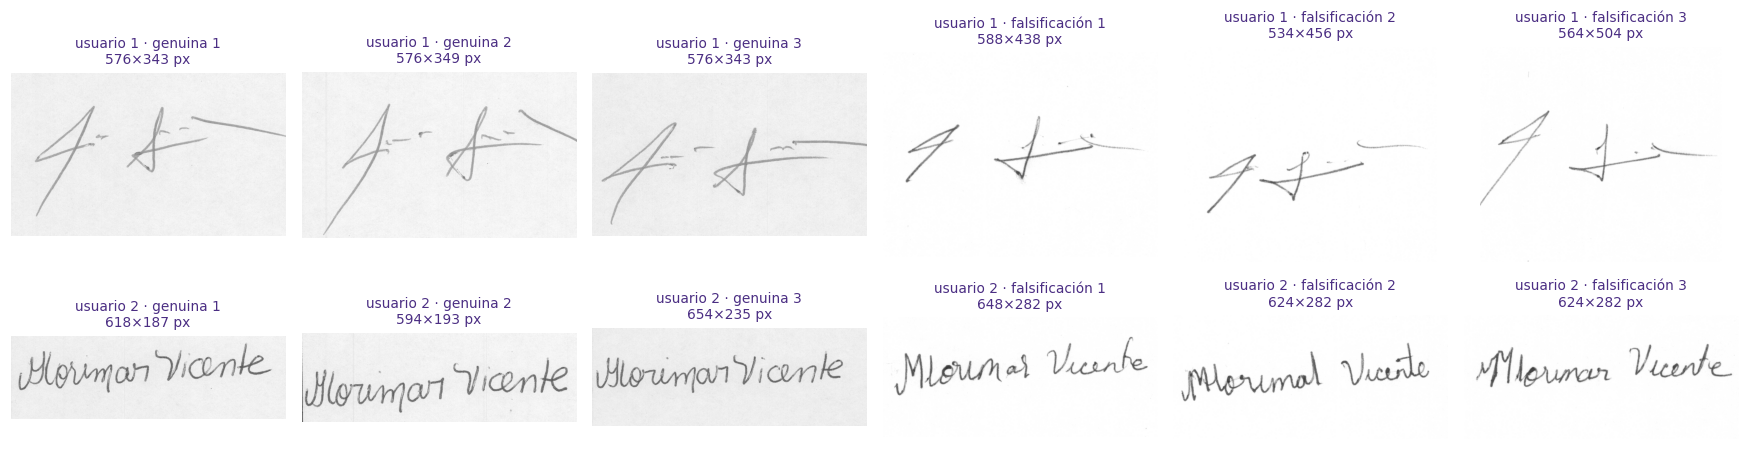

In [3]:
fig, ejes = plt.subplots(2, 6, figsize=(16, 4.6))
for fila, u in enumerate(USUARIOS_DESARROLLO[:2]):
    for col in range(6):
        clase, n = ('g', col + 1) if col < 3 else ('f', col - 2)
        img = cv2.imread(str(ruta(clase, u, n)))
        ejes[fila, col].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        etiqueta = 'genuina' if clase == 'g' else 'falsificación'
        ejes[fila, col].set_title(f'usuario {u} · {etiqueta} {n}\n{img.shape[1]}×{img.shape[0]} px', fontsize=9)
        ejes[fila, col].axis('off')
plt.tight_layout()
plt.show()

## 2. Preprocesamiento

Para cada firma hacemos estos pasos, siempre los mismos:

1. **Escala de grises** (`cv2.cvtColor`). Las imágenes vienen en BGR pero la tinta es solo un trazo oscuro.
2. **Filtrado**: mediana 3×3 para quitar ruido tipo sal y pimienta y gaussiano 3×3 para suavizar un poco el trazo.
3. **Binarización de Otsu** invertida, de forma que la tinta queda en 255 y el fondo en 0. Antes de usar la función de OpenCV implementamos Otsu a mano.
4. **Limpieza** de componentes conexas muy pequeñas (menos de 15 píxeles), que son motas y no trazo.
5. **Recorte** a la caja que contiene la tinta (`cv2.boundingRect`), para que la posición de la firma en la hoja no influya.

### 2.1 Otsu hecho a mano
Para cada umbral T separamos los píxeles en fondo (nivel < T) y primer plano (nivel ≥ T), calculamos el peso, la media y la varianza de cada clase, y nos quedamos con el T que minimiza σ²_W = W_b·σ²_b + W_f·σ²_f.

In [4]:
def a_gris(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

def suavizar(gris):
    return cv2.GaussianBlur(cv2.medianBlur(gris, 3), (3, 3), 0)

def otsu_manual(gris):
    """Devuelve el umbral T (clases: nivel < T y nivel >= T) y la curva de varianza intragrupal."""
    h = np.bincount(gris.ravel(), minlength=256).astype(float)
    niveles = np.arange(256)
    N = h.sum()
    var_w = np.full(256, np.inf)
    for T in range(1, 256):
        hb, hf = h[:T], h[T:]
        if hb.sum() == 0 or hf.sum() == 0:
            continue
        Wb, Wf = hb.sum() / N, hf.sum() / N
        mb = (niveles[:T] * hb).sum() / hb.sum()
        mf = (niveles[T:] * hf).sum() / hf.sum()
        vb = ((niveles[:T] - mb) ** 2 * hb).sum() / hb.sum()
        vf = ((niveles[T:] - mf) ** 2 * hf).sum() / hf.sum()
        var_w[T] = Wb * vb + Wf * vf
    return int(np.argmin(var_w)), var_w

# Comprobación con 30 firmas: nuestro T debe coincidir con el umbral de OpenCV
# (OpenCV marca como primer plano los píxeles > t, es decir, >= t+1, así que T = t + 1)
coinciden = 0
muestra = [(c, u, n) for u in USUARIOS_DESARROLLO[:5] for c in 'gf' for n in (1, 2, 3)]
for c, u, n in muestra:
    g = suavizar(a_gris(cv2.imread(str(ruta(c, u, n)))))
    t_cv, _ = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    T, _ = otsu_manual(g)
    coinciden += (T == int(t_cv) + 1)
print(f'Umbral manual = umbral de OpenCV + 1 en {coinciden} de {len(muestra)} firmas')

Umbral manual = umbral de OpenCV + 1 en 30 de 30 firmas


### 2.2 Pipeline completo
Ahora juntamos los pasos en `preprocesar` y los vemos uno a uno en una firma. El último panel es el histograma de la imagen suavizada con el umbral de Otsu y la curva de σ²_W, cuyo mínimo es el umbral elegido.

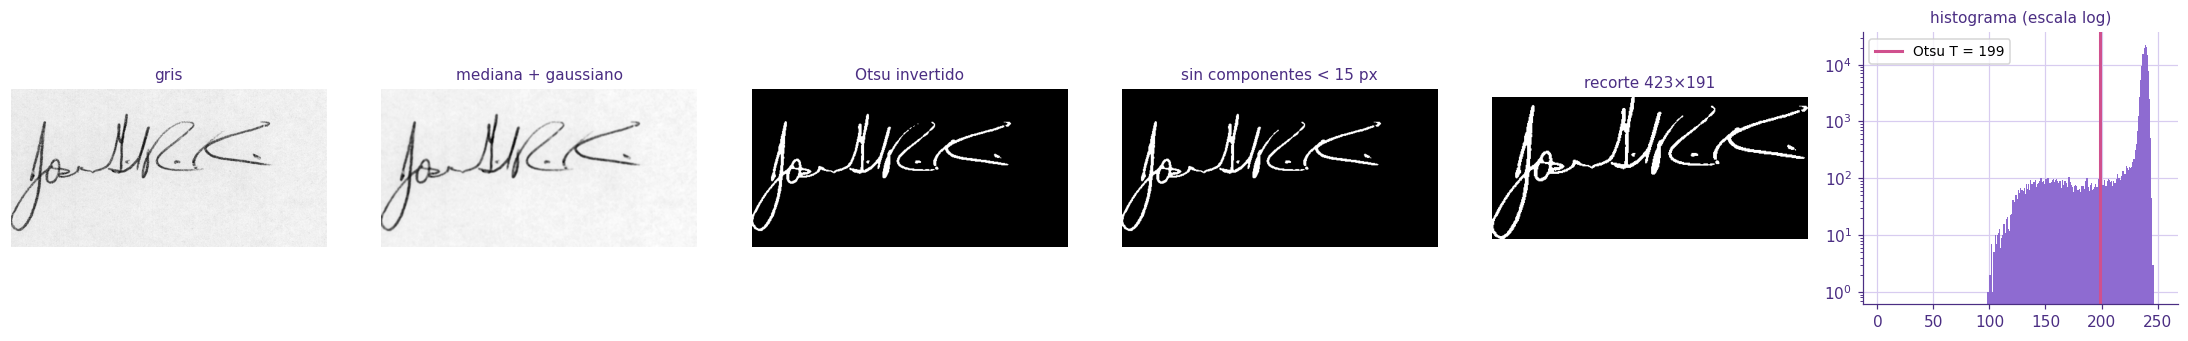

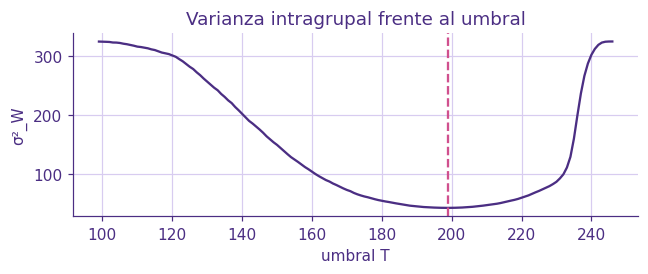

In [5]:
AREA_MINIMA = 15   # píxeles; componentes más pequeñas se consideran ruido

def binarizar(gris):
    """Otsu invertido: tinta = 255, fondo = 0."""
    _, b = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return b

def limpiar(b, area_minima=AREA_MINIMA):
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    mantener = stats[:, cv2.CC_STAT_AREA] >= area_minima
    mantener[0] = False                      # la etiqueta 0 es el fondo
    return (mantener[etiquetas] * 255).astype(np.uint8)

def recortar(b):
    x, y, w, h = cv2.boundingRect(cv2.findNonZero(b))
    return b[y:y + h, x:x + w]

def preprocesar(img_bgr):
    gris = suavizar(a_gris(img_bgr))
    return recortar(limpiar(binarizar(gris)))

# Visualización paso a paso
img = cv2.imread(str(ruta('g', USUARIOS_DESARROLLO[2], 4)))
gris0 = a_gris(img)
gris1 = suavizar(gris0)
bin0 = binarizar(gris1)
bin1 = limpiar(bin0)
rec = recortar(bin1)
T, var_w = otsu_manual(gris1)

fig, ejes = plt.subplots(1, 6, figsize=(20, 3.2))
pasos = [(gris0, 'gris'), (gris1, 'mediana + gaussiano'), (bin0, 'Otsu invertido'),
         (bin1, f'sin componentes < {AREA_MINIMA} px'), (rec, f'recorte {rec.shape[1]}×{rec.shape[0]}')]
for ax, (im, tit) in zip(ejes[:5], pasos):
    ax.imshow(im, cmap='gray'); ax.set_title(tit, fontsize=10); ax.axis('off')
h = np.bincount(gris1.ravel(), minlength=256)
ejes[5].bar(np.arange(256), h, color=LILA, width=1.0)
ejes[5].set_yscale('log')
ejes[5].axvline(T, color=ROSA, lw=2, label=f'Otsu T = {T}')
ejes[5].set_title('histograma (escala log)', fontsize=10); ejes[5].legend(fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(np.arange(1, 256), var_w[1:], color=LILA_OSCURO)
ax.axvline(T, color=ROSA, ls='--'); ax.set_xlabel('umbral T'); ax.set_ylabel('σ²_W')
ax.set_title('Varianza intragrupal frente al umbral')
plt.tight_layout(); plt.show()

## 3. Extracción de características

Sobre la firma binaria y recortada calculamos **35 características**, todas sencillas y calculadas con OpenCV y NumPy:

| Grupo | Características | Nº |
|---|---|---|
| Tamaño | logaritmo del ancho, logaritmo del alto, relación ancho/alto | 3 |
| Tinta | densidad de tinta (píxeles de tinta / área de la caja) y logaritmo del nº de píxeles de tinta | 2 |
| Centroide | posición (x, y) del centro de masa, normalizada por el ancho y el alto (`cv2.moments`) | 2 |
| Componentes conexas | nº de componentes y fracción de tinta que ocupa la mayor (`connectedComponentsWithStats`) | 2 |
| Rejilla de densidad | la firma se reescala a 48×24 con `cv2.resize` (INTER_AREA) y se promedia en una rejilla de 3 filas × 6 columnas | 18 |
| Orientación del trazo | histograma de 8 orientaciones del gradiente de Sobel, ponderado por su magnitud | 8 |

Usamos el logaritmo en el tamaño porque las diferencias de tamaño son multiplicativas (una firma el doble de grande es "igual de distinta" sea pequeña o grande). La rejilla y el histograma de orientaciones normalizan por la cantidad de tinta, así que describen **cómo** se reparte el trazo y no cuánto hay.

In [6]:
NOMBRES = (['log_ancho', 'log_alto', 'rel_ancho_alto', 'densidad_tinta', 'log_pixeles_tinta',
            'centroide_x', 'centroide_y', 'n_componentes', 'frac_componente_mayor']
           + [f'rejilla_{i}{j}' for i in range(3) for j in range(6)]
           + [f'orientacion_{k}' for k in range(8)])

def extraer_caracteristicas(b):
    alto, ancho = b.shape
    tinta = b > 0
    n_tinta = tinta.sum()

    # Centroide (momentos de orden 1 sobre la imagen binaria)
    M = cv2.moments(b, binaryImage=True)
    cx, cy = M['m10'] / M['m00'] / ancho, M['m01'] / M['m00'] / alto

    # Componentes conexas
    n, _, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]

    # Rejilla de densidad 3x6 a partir de una versión 48x24 de la firma
    peque = cv2.resize(b, (48, 24), interpolation=cv2.INTER_AREA) / 255.0
    rejilla = peque.reshape(3, 8, 6, 8).mean(axis=(1, 3)).ravel()

    # Orientación del trazo con Sobel (se suaviza un poco la binaria para tener gradientes estables)
    suave = cv2.GaussianBlur(b, (5, 5), 0).astype(np.float32)
    gx, gy = cv2.Sobel(suave, cv2.CV_32F, 1, 0), cv2.Sobel(suave, cv2.CV_32F, 0, 1)
    magnitud = np.sqrt(gx ** 2 + gy ** 2)
    angulo = np.arctan2(gy, gx) % np.pi                       # orientación sin sentido: [0, pi)
    hist, _ = np.histogram(angulo, bins=8, range=(0, np.pi), weights=magnitud)
    hist = hist / hist.sum()

    return np.concatenate([
        [np.log(ancho), np.log(alto), ancho / alto],
        [n_tinta / (ancho * alto), np.log(n_tinta)],
        [cx, cy],
        [n - 1, areas.max() / areas.sum()],
        rejilla, hist])

assert len(NOMBRES) == len(extraer_caracteristicas(rec))
print(len(NOMBRES), 'características')

35 características


Calculamos las características de **todas** las firmas (43 usuarios × 24 genuinas × 24 falsificaciones) y las guardamos en un diccionario con clave `(clase, usuario, n)`.

In [7]:
CARACT = {}
for u in USUARIOS:
    for clase in 'gf':
        for n in range(1, 25):
            CARACT[(clase, u, n)] = extraer_caracteristicas(preprocesar(cv2.imread(str(ruta(clase, u, n)))))

print(len(CARACT), 'firmas procesadas')
assert np.isfinite(np.array(list(CARACT.values()))).all()

pd.DataFrame([CARACT[('g', USUARIOS[0], n)] for n in range(1, 6)], columns=NOMBRES,
             index=[f'genuina {n}' for n in range(1, 6)]).iloc[:, :9].round(3)

2064 firmas procesadas


,log_ancho,log_alto,rel_ancho_alto,densidad_tinta,log_pixeles_tinta,centroide_x,centroide_y,n_componentes,frac_componente_mayor
genuina 1,6.265,5.438,2.287,0.051,8.730,0.377,0.345,5.0,0.423
genuina 2,6.275,5.609,1.945,0.046,8.797,0.451,0.338,8.0,0.408
genuina 3,6.321,5.366,2.598,0.059,8.862,0.424,0.376,7.0,0.405
genuina 4,6.263,5.481,2.188,0.049,8.729,0.408,0.351,6.0,0.418
genuina 5,6.284,5.468,2.262,0.053,8.823,0.466,0.367,8.0,0.461


Una comprobación rápida: ¿separan algo estas características? Para cuatro de ellas comparamos, en los usuarios de desarrollo, la distancia de cada firma a la media de las 10 referencias de su usuario (medida en desviaciones típicas globales). Si la característica sirve, las falsificaciones deberían quedar algo más lejos que las genuinas.

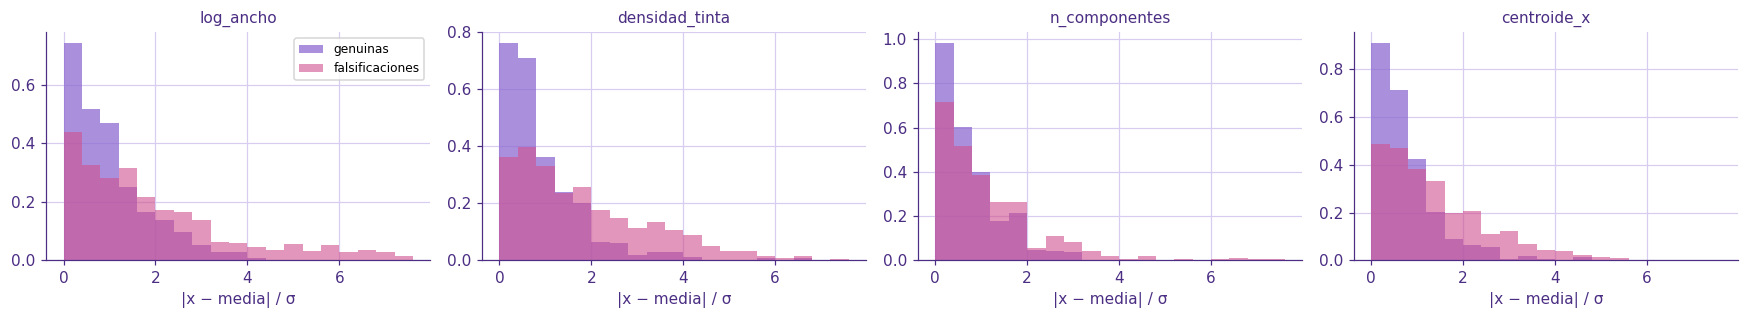

In [8]:
sigma_tmp = np.sqrt(np.mean([np.array([CARACT[('g', u, n)] for n in REFERENCIAS]).var(0, ddof=1)
                             for u in USUARIOS_DESARROLLO], axis=0))
dist = {'genuinas': [], 'falsificaciones': []}
for u in USUARIOS_DESARROLLO:
    mu = np.array([CARACT[('g', u, n)] for n in REFERENCIAS]).mean(0)
    for n in GENUINAS_TEST:
        dist['genuinas'].append(np.abs(CARACT[('g', u, n)] - mu) / sigma_tmp)
    for n in FALSIFICACIONES:
        dist['falsificaciones'].append(np.abs(CARACT[('f', u, n)] - mu) / sigma_tmp)
dist = {k: np.array(v) for k, v in dist.items()}

fig, ejes = plt.subplots(1, 4, figsize=(16, 3))
for ax, nombre in zip(ejes, ['log_ancho', 'densidad_tinta', 'n_componentes', 'centroide_x']):
    j = NOMBRES.index(nombre)
    ax.hist(dist['genuinas'][:, j], bins=np.arange(0, 8, 0.4), density=True, alpha=0.75, color=LILA, label='genuinas')
    ax.hist(dist['falsificaciones'][:, j], bins=np.arange(0, 8, 0.4), density=True, alpha=0.6, color=ROSA, label='falsificaciones')
    ax.set_title(nombre, fontsize=10); ax.set_xlabel('|x − media| / σ')
ejes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Patrón de usuario y puntuación de similitud

### Patrón
Con las 10 firmas de referencia de un usuario calculamos, para cada característica, la **media μ** y la **desviación típica σ**. Ese par de vectores es el patrón.

### Puntuación
Para una firma nueva con características **x**:

1. Diferencia normalizada: z_j = |x_j − μ_j| / σ_ef,j
2. Distancia ponderada: d = Σ w_j · z_j / Σ w_j
3. Puntuación de similitud: **s = exp(−d)**, un valor en (0, 1] que es 1 cuando coincide con el patrón y baja hacia 0 cuando se parece menos.

Con solo 10 referencias, la σ de cada usuario es poco fiable (a veces casi 0 y entonces cualquier diferencia parece enorme). Por eso usamos una σ efectiva que mezcla la del usuario con la variación típica de firma dentro de un mismo usuario, calculada con los usuarios de desarrollo:

σ²_ef = α · σ²_usuario + (1 − α) · σ²_global

- **α** es el primer hiperparámetro (con α = 1 solo se usa la σ del usuario, con α = 0 solo la global). Lo elegimos en desarrollo.
- **w_j** son los pesos de las características. No todas separan igual de bien, así que damos más peso a las que mejor distinguen genuinas de impostoras con una razón de Fisher: (diferencia de medias)² / (suma de varianzas). Se calculan en desarrollo con comparaciones todas con todas, y para los impostores se da el mismo peso a las falsificaciones hábiles que a las aleatorias.

In [9]:
def crear_patron(usuario):
    """Media y desviación típica de las 10 firmas de referencia."""
    R = np.array([CARACT[('g', usuario, n)] for n in REFERENCIAS])
    return R.mean(axis=0), R.std(axis=0, ddof=1)

def sigma_global_de(usuarios):
    """Variación típica de cada característica dentro de un mismo usuario."""
    return np.sqrt(np.mean([crear_patron(u)[1] ** 2 for u in usuarios], axis=0))

def construir_matriz(usuarios):
    """Matriz con las características de todas las firmas (24 genuinas + 24 falsificaciones por usuario)."""
    filas, X = [], []
    for u in usuarios:
        for clase in 'gf':
            for n in range(1, 25):
                filas.append((u, clase, n)); X.append(CARACT[(clase, u, n)])
    return np.array(X), pd.DataFrame(filas, columns=['usuario', 'clase', 'n'])

def comparar_todos(usuarios, alfa, sigma_global, suelo=0.1):
    """Compara el patrón de cada usuario con las firmas de todos los usuarios del grupo.
    Devuelve la matriz de diferencias normalizadas Z (una fila por comparación) y su descripción:
      - genuina:   genuinas 11-24 del propio usuario
      - hábil:     las 24 falsificaciones hábiles del propio usuario
      - aleatoria: todas las firmas (genuinas y falsificaciones) de los demás usuarios
    Las genuinas 1-10 del propio usuario no se comparan porque son las que forman el patrón."""
    X, meta = construir_matriz(usuarios)
    Zs, descr = [], []
    for u in usuarios:
        mu, sd = crear_patron(u)
        # σ efectiva; el suelo evita dividir por casi cero
        se = np.maximum(np.sqrt(alfa * sd ** 2 + (1 - alfa) * sigma_global ** 2), suelo * sigma_global)
        propio = (meta.usuario == u).values
        es_gen = propio & (meta.clase == 'g').values & (meta.n >= 11).values
        es_hab = propio & (meta.clase == 'f').values
        es_ale = ~propio
        sel = es_gen | es_hab | es_ale
        Zs.append(np.abs(X[sel] - mu) / se)
        tipo = np.where(es_gen[sel], 'genuina', np.where(es_hab[sel], 'hábil', 'aleatoria'))
        d = meta[sel].copy()
        d.insert(0, 'patron', u); d['tipo'] = tipo
        descr.append(d)
    return np.vstack(Zs), pd.concat(descr, ignore_index=True)

def pesos_fisher(Z, tipo):
    """Razón de Fisher por característica (genuinas frente a impostores hábiles y aleatorios a partes iguales)."""
    Zg, Zh, Za = Z[tipo == 'genuina'], Z[tipo == 'hábil'], Z[tipo == 'aleatoria']
    mh, ma = Zh.mean(0), Za.mean(0)
    m_imp = (mh + ma) / 2
    var_imp = 0.5 * (Zh.var(0) + (mh - m_imp) ** 2) + 0.5 * (Za.var(0) + (ma - m_imp) ** 2)
    f = (m_imp - Zg.mean(0)) ** 2 / (var_imp + Zg.var(0))
    return f / f.mean()

def puntuar(Z, pesos):
    """s = exp(-d), con d la media ponderada de las diferencias normalizadas."""
    return np.exp(-(Z @ pesos) / pesos.sum())

# Variación típica dentro de cada usuario (solo desarrollo; se mantiene fija después)
SIGMA_GLOBAL = sigma_global_de(USUARIOS_DESARROLLO)
print('σ global calculada con', len(USUARIOS_DESARROLLO), 'usuarios de desarrollo')

σ global calculada con 30 usuarios de desarrollo


## 5. Métricas biométricas hechas a mano

Las curvas y los errores no salen de ninguna función de librería; los calculamos nosotros:

- **FRR(t)** (tasa de falso rechazo): fracción de firmas genuinas con puntuación **< t**.
- **FAR(t)** (tasa de falsa aceptación): fracción de impostores con puntuación **≥ t**.
- **EER**: punto donde FRR = FAR. Lo buscamos recorriendo los umbrales y, entre los dos puntos donde las curvas se cruzan, interpolamos linealmente.
- **Curva DET**: FRR frente a FAR con ambos ejes en escala de desviaciones normales (probit), que convierte las curvas en algo casi recto y permite ver mejor la zona de errores pequeños.

Como tenemos dos tipos de impostores, usamos tres escenarios:
- **Hábiles**: solo las falsificaciones hábiles (el protocolo del enunciado).
- **Aleatorias**: firmas de otros usuarios (todas con todas).
- **Equilibrado**: FAR = media de las dos. Lo usamos para ajustar el sistema, para que las aleatorias, que son muchísimas más, no tapen a las hábiles.

In [10]:
UMBRALES = np.linspace(0, 1, 2001)

def frr_en(gen, t):
    return np.mean(gen < t)

def far_en(imp, t):
    return np.mean(imp >= t)

def curva_frr(gen, umbrales=UMBRALES):
    g = np.sort(gen)
    return np.searchsorted(g, umbrales, side='left') / len(g)          # nº de genuinas con s < t

def curva_far(imp, umbrales=UMBRALES):
    i = np.sort(imp)
    return 1 - np.searchsorted(i, umbrales, side='left') / len(i)      # nº de impostores con s >= t

def calcular_eer(far, frr, umbrales=UMBRALES):
    """Cruce de FAR y FRR con interpolación lineal. Devuelve (EER, umbral del EER)."""
    k = int(np.argmax(far <= frr))             # primer umbral donde FAR ya no supera a FRR
    if k == 0:
        return (far[0] + frr[0]) / 2, umbrales[0]
    d0, d1 = frr[k - 1] - far[k - 1], frr[k] - far[k]    # d0 < 0 <= d1
    p = -d0 / (d1 - d0)
    return frr[k - 1] + p * (frr[k] - frr[k - 1]), umbrales[k - 1] + p * (umbrales[k] - umbrales[k - 1])

def curvas(s, tipo):
    frr = curva_frr(s[tipo == 'genuina'])
    far_h = curva_far(s[tipo == 'hábil'])
    far_a = curva_far(s[tipo == 'aleatoria'])
    return {'frr': frr, 'far_h': far_h, 'far_a': far_a, 'far_b': (far_h + far_a) / 2}

def eers(c):
    return {k: calcular_eer(c['far_' + k], c['frr']) for k in ('h', 'a', 'b')}

# --- Gráficas dibujadas a partir de nuestras curvas ---
_nd = NormalDist()
def probit(p, minimo=0.001):
    p = np.clip(np.atleast_1d(np.asarray(p, float)), minimo, 1 - minimo)
    return np.array([_nd.inv_cdf(x) for x in p])

MARCAS_DET = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8]
ESTILO = {'h': (ROSA, 'Hábiles'), 'a': (LILA, 'Aleatorias'), 'b': (LILA_OSCURO, 'Equilibrado')}

def grafica_det(ax, c, titulo, umbral=None, s=None, tipo=None):
    e = eers(c)
    for k, (color, nombre) in ESTILO.items():
        ax.plot(probit(c['far_' + k]), probit(c['frr']), color=color, lw=2,
                label=f'{nombre} (EER = {100 * e[k][0]:.1f} %)')
        ax.plot(probit(e[k][0]), probit(e[k][0]), 'o', color=color, ms=6)
        if umbral is not None and k != 'b':
            gen = s[tipo == 'genuina']; imp = s[tipo == ('hábil' if k == 'h' else 'aleatoria')]
            ax.plot(probit(far_en(imp, umbral)), probit(frr_en(gen, umbral)), '*', color=color, ms=13,
                    markeredgecolor='black', markeredgewidth=0.6)
    lim = probit([0.001, 0.9])
    ax.plot(lim, lim, ls='--', color=GRIS, lw=1)
    ax.set_xticks(probit(MARCAS_DET)); ax.set_xticklabels([f'{100 * m:g}' for m in MARCAS_DET])
    ax.set_yticks(probit(MARCAS_DET)); ax.set_yticklabels([f'{100 * m:g}' for m in MARCAS_DET])
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('FAR (%)'); ax.set_ylabel('FRR (%)'); ax.set_title(titulo)
    ax.legend(fontsize=8, loc='upper right')

def grafica_far_frr(ax, c, titulo, umbral=None):
    e = eers(c)
    ax.plot(UMBRALES, 100 * c['frr'], color=LILA_OSCURO, lw=2.2, label='FRR')
    ax.plot(UMBRALES, 100 * c['far_h'], color=ROSA, lw=1.8, label='FAR hábiles')
    ax.plot(UMBRALES, 100 * c['far_a'], color=LILA, lw=1.8, label='FAR aleatorias')
    ax.plot(UMBRALES, 100 * c['far_b'], color=GRIS, lw=1.8, ls='--', label='FAR equilibrado')
    ax.plot(e['b'][1], 100 * e['b'][0], 'o', color='black', ms=7, label=f'EER equilibrado = {100 * e["b"][0]:.1f} %')
    if umbral is not None:
        ax.axvline(umbral, color='black', ls=':', lw=1.3, label=f'umbral fijado = {umbral:.3f}')
    ax.set_xlabel('umbral t'); ax.set_ylabel('error (%)'); ax.set_title(titulo)
    ax.set_xlim(0, 1); ax.set_ylim(0, 100); ax.legend(fontsize=8)

# Prueba con datos inventados: dos nubes de puntuaciones; el EER debe quedar entre ambas medias
rng = np.random.default_rng(0)
prueba_gen, prueba_imp = rng.normal(0.7, 0.1, 5000), rng.normal(0.4, 0.1, 5000)
e, t = calcular_eer(curva_far(prueba_imp), curva_frr(prueba_gen))
print(f'Prueba: EER = {100 * e:.2f} % (teórico 6.68 %) en t = {t:.3f} (teórico 0.550)')

Prueba: EER = 6.39 % (teórico 6.68 %) en t = 0.550 (teórico 0.550)


## 6. Ajuste con los usuarios de desarrollo

Aquí se decide todo lo que después queda fijo. Usamos los 30 usuarios de desarrollo con comparaciones todas con todas: cada patrón se compara con sus genuinas 11-24, con sus 24 falsificaciones hábiles y con las firmas de los otros 29 usuarios.

### 6.1 Hiperparámetro α
Probamos cinco valores de α. Para cada uno calculamos los pesos de Fisher y el EER equilibrado, y como referencia también el EER con pesos uniformes (todas las características con el mismo peso) para ver si ponderar sirve de algo. Nos quedamos con el α de menor EER equilibrado con Fisher.

,"EER equilibrado, pesos uniformes (%)","EER equilibrado, pesos Fisher (%)",EER hábiles (%),EER aleatorias (%)
α,,,,
0.00,12.86,10.42,14.72,2.62
0.25,12.38,9.76,14.76,2.31
0.50,12.14,9.76,15.71,2.38
0.75,12.02,10.40,16.25,2.62
1.00,12.64,11.03,17.89,3.81


α elegido: 0.25


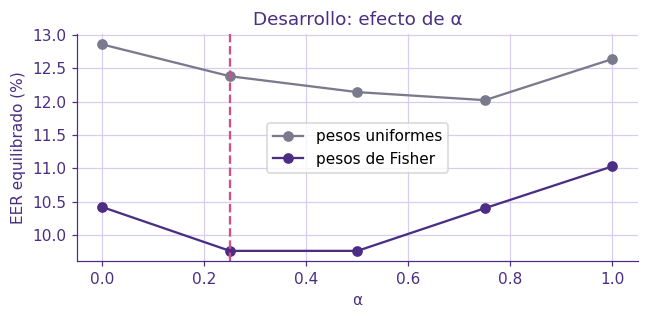

In [11]:
GRID_ALFA = [0.0, 0.25, 0.5, 0.75, 1.0]
filas = []
for alfa in GRID_ALFA:
    Z, desc = comparar_todos(USUARIOS_DESARROLLO, alfa, SIGMA_GLOBAL)
    tipo = desc.tipo.values
    w_fisher = pesos_fisher(Z, tipo)
    fila = {'α': alfa}
    for nombre, w in (('uniformes', np.ones(len(NOMBRES))), ('Fisher', w_fisher)):
        e = eers(curvas(puntuar(Z, w), tipo))
        fila[f'EER equilibrado, pesos {nombre} (%)'] = 100 * e['b'][0]
        if nombre == 'Fisher':
            fila['EER hábiles (%)'] = 100 * e['h'][0]
            fila['EER aleatorias (%)'] = 100 * e['a'][0]
    filas.append(fila)

tabla_alfa = pd.DataFrame(filas).set_index('α')
display(tabla_alfa.round(2))

ALFA = tabla_alfa['EER equilibrado, pesos Fisher (%)'].idxmin()
print(f'α elegido: {ALFA}')

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(tabla_alfa.index, tabla_alfa['EER equilibrado, pesos uniformes (%)'], 'o-', color=GRIS, label='pesos uniformes')
ax.plot(tabla_alfa.index, tabla_alfa['EER equilibrado, pesos Fisher (%)'], 'o-', color=LILA_OSCURO, label='pesos de Fisher')
ax.axvline(ALFA, color=ROSA, ls='--')
ax.set_xlabel('α'); ax.set_ylabel('EER equilibrado (%)'); ax.set_title('Desarrollo: efecto de α'); ax.legend()
plt.tight_layout(); plt.show()

### 6.2 Pesos y umbral global
Con el α elegido volvemos a calcular los pesos de Fisher y las puntuaciones de desarrollo. El **umbral global** es la puntuación donde FRR y FAR equilibrado se cruzan (EER) en desarrollo. A partir de aquí **α, pesos, σ global y umbral quedan fijos**.

Umbral fijado (EER equilibrado en desarrollo): 0.3115
Características con más peso: log_pixeles_tinta (2.31), orientacion_0 (2.14), log_alto (1.72), densidad_tinta (1.60), log_ancho (1.47), orientacion_7 (1.47)


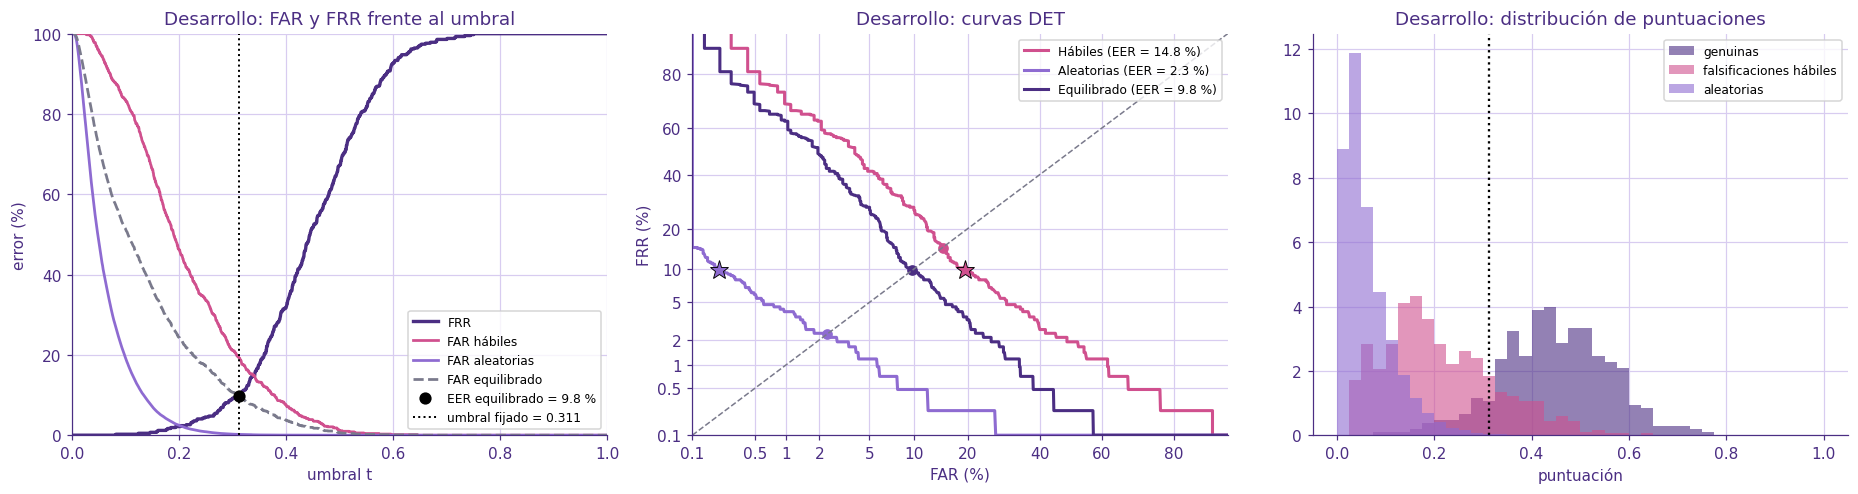

In [12]:
Z_dev, desc_dev = comparar_todos(USUARIOS_DESARROLLO, ALFA, SIGMA_GLOBAL)
PESOS = pesos_fisher(Z_dev, desc_dev.tipo.values)
s_dev = puntuar(Z_dev, PESOS)
c_dev = curvas(s_dev, desc_dev.tipo.values)
e_dev = eers(c_dev)
UMBRAL = float(e_dev['b'][1])

print(f'Umbral fijado (EER equilibrado en desarrollo): {UMBRAL:.4f}')
print('Características con más peso:', ', '.join(f'{NOMBRES[j]} ({PESOS[j]:.2f})' for j in np.argsort(-PESOS)[:6]))

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.6))
grafica_far_frr(ejes[0], c_dev, 'Desarrollo: FAR y FRR frente al umbral', UMBRAL)
grafica_det(ejes[1], c_dev, 'Desarrollo: curvas DET', UMBRAL, s_dev, desc_dev.tipo.values)
for tipo_, color, nombre in (('genuina', LILA_OSCURO, 'genuinas'), ('hábil', ROSA, 'falsificaciones hábiles'), ('aleatoria', LILA, 'aleatorias')):
    ejes[2].hist(s_dev[desc_dev.tipo.values == tipo_], bins=np.linspace(0, 1, 41), density=True, alpha=0.6, color=color, label=nombre)
ejes[2].axvline(UMBRAL, color='black', ls=':'); ejes[2].set_xlabel('puntuación'); ejes[2].set_title('Desarrollo: distribución de puntuaciones')
ejes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Evaluación con los usuarios de evaluación

Con los parámetros fijados evaluamos a los 13 usuarios de evaluación. Para cada uno solo construimos el patrón con sus 10 genuinas de referencia; α, la σ global, los pesos y el umbral vienen de desarrollo y no se tocan. Las comparaciones todas con todas se hacen entre los 13 usuarios de evaluación.

In [13]:
Z_ev, desc_ev = comparar_todos(USUARIOS_EVALUACION, ALFA, SIGMA_GLOBAL)
s_ev = puntuar(Z_ev, PESOS)
res_ev = desc_ev.assign(puntuacion=s_ev)
tipo_ev = res_ev.tipo.values
print(res_ev.groupby('tipo').size().rename('comparaciones').to_frame())

c_ev = curvas(s_ev, tipo_ev)
e_ev = eers(c_ev)

def resumen(s, tipo, c, e, umbral):
    gen = s[tipo == 'genuina']
    filas = []
    for k, nombre in (('h', 'Falsificaciones hábiles'), ('a', 'Aleatorias (todas con todas)'), ('b', 'Equilibrado')):
        if k == 'b':
            far = (far_en(s[tipo == 'hábil'], umbral) + far_en(s[tipo == 'aleatoria'], umbral)) / 2
        else:
            far = far_en(s[tipo == ('hábil' if k == 'h' else 'aleatoria')], umbral)
        filas.append({'Escenario': nombre, 'EER (%)': 100 * e[k][0], 'umbral del EER': e[k][1],
                      'FAR con umbral fijado (%)': 100 * far, 'FRR con umbral fijado (%)': 100 * frr_en(gen, umbral)})
    return pd.DataFrame(filas).set_index('Escenario')

print(f'\nUmbral fijado en desarrollo: {UMBRAL:.4f}')
display(resumen(s_ev, tipo_ev, c_ev, e_ev, UMBRAL).round(2))

           comparaciones
tipo                    
aleatoria           7488
genuina              182
hábil                312

Umbral fijado en desarrollo: 0.3115


,EER (%),umbral del EER,FAR con umbral fijado (%),FRR con umbral fijado (%)
Escenario,,,,
Falsificaciones hábiles,12.15,0.32,13.14,10.44
Aleatorias (todas con todas),1.65,0.20,0.08,10.44
Equilibrado,7.93,0.30,6.61,10.44


### Matriz de confusión
Con el umbral fijado, cada comparación acaba en aceptar o rechazar. La matriz de confusión cruza esa decisión con la clase real y permite ver directamente los falsos positivos (impostores aceptados → FAR) y los falsos negativos (genuinas rechazadas → FRR).

Mostramos dos matrices: una solo con el escenario más duro (genuinas frente a falsificaciones hábiles) y otra con todas las comparaciones de evaluación.


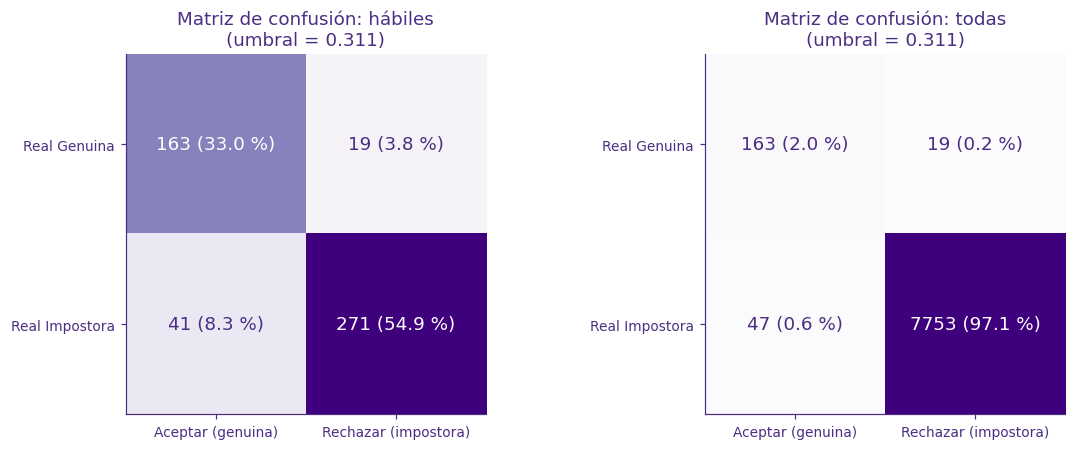

Escenario hábil -> verdaderos positivos: 163, falsos negativos (FRR): 19, falsos positivos (FAR): 41, verdaderos negativos: 271
Todas        -> verdaderos positivos: 163, falsos negativos (FRR): 19, falsos positivos (FAR): 47, verdaderos negativos: 7753


Decisión,Aceptar (genuina),Rechazar (impostora)
Real,,
Real Genuina,163,19
Real Impostora,41,271


Decisión,Aceptar (genuina),Rechazar (impostora)
Real,,
Real Genuina,163,19
Real Impostora,47,7753


In [14]:
def matriz_confusion(prediccion, real, etiquetas=(1, 0), titulos=('Genuina', 'Impostora')):
    """Matriz de confusión 2x2: filas = real, columnas = decisión del sistema.
    etiquetas: valor de 'real' que cuenta como genuina / impostora.
    Devuelve el DataFrame con [[VP, FN], [FP, VN]]."""
    M = np.zeros((2, 2), dtype=int)
    for p, r in zip(prediccion, real):
        fila = 0 if r == etiquetas[0] else 1          # real
        col = 0 if p else 1                            # decisión: True = aceptar
        M[fila, col] += 1
    df = pd.DataFrame(M, index=[f'Real {t}' for t in titulos],
                      columns=[f'Aceptar ({titulos[0].lower()})', f'Rechazar ({titulos[1].lower()})'])
    df.index.name, df.columns.name = 'Real', 'Decisión'
    return df

def dibuja_matriz(df, ax, titulo, fmt_pct=True):
    M = df.values
    total = M.sum()
    img = ax.imshow(M, cmap='Purples', vmin=0)
    for i in range(2):
        for j in range(2):
            texto = f'{M[i, j]} ({100 * M[i, j] / total:.1f} %)' if fmt_pct else str(M[i, j])
            ax.text(j, i, texto, ha='center', va='center', fontsize=12,
                    color='white' if M[i, j] > M.max() * 0.55 else LILA_OSCURO)
    ax.set_xticks([0, 1]); ax.set_xticklabels(df.columns, fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(df.index, fontsize=9)
    ax.set_title(titulo); ax.grid(False)

decision_ev = s_ev >= UMBRAL                     # True = aceptada como genuina

# a) Escenario duro: genuinas frente a falsificaciones hábiles
duro = tipo_ev != 'aleatoria'
mc_duro = matriz_confusion(decision_ev[duro], (tipo_ev[duro] == 'genuina').astype(int))

# b) Todas las comparaciones: genuinas frente a cualquier impostora
mc_todo = matriz_confusion(decision_ev, (tipo_ev == 'genuina').astype(int),
                           titulos=('Genuina', 'Impostora'))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
dibuja_matriz(mc_duro, ejes[0], f'Matriz de confusión: hábiles\n(umbral = {UMBRAL:.3f})')
dibuja_matriz(mc_todo, ejes[1], f'Matriz de confusión: todas\n(umbral = {UMBRAL:.3f})')
plt.tight_layout(); plt.show()

VP, FN = mc_duro.iloc[0, 0], mc_duro.iloc[0, 1]
FP, VN = mc_duro.iloc[1, 0], mc_duro.iloc[1, 1]
print(f'Escenario hábil -> verdaderos positivos: {VP}, falsos negativos (FRR): {FN}, '
      f'falsos positivos (FAR): {FP}, verdaderos negativos: {VN}')
VP2, FN2 = mc_todo.iloc[0, 0], mc_todo.iloc[0, 1]
FP2, VN2 = mc_todo.iloc[1, 0], mc_todo.iloc[1, 1]
print(f'Todas        -> verdaderos positivos: {VP2}, falsos negativos (FRR): {FN2}, '
      f'falsos positivos (FAR): {FP2}, verdaderos negativos: {VN2}')
display(mc_duro, mc_todo)

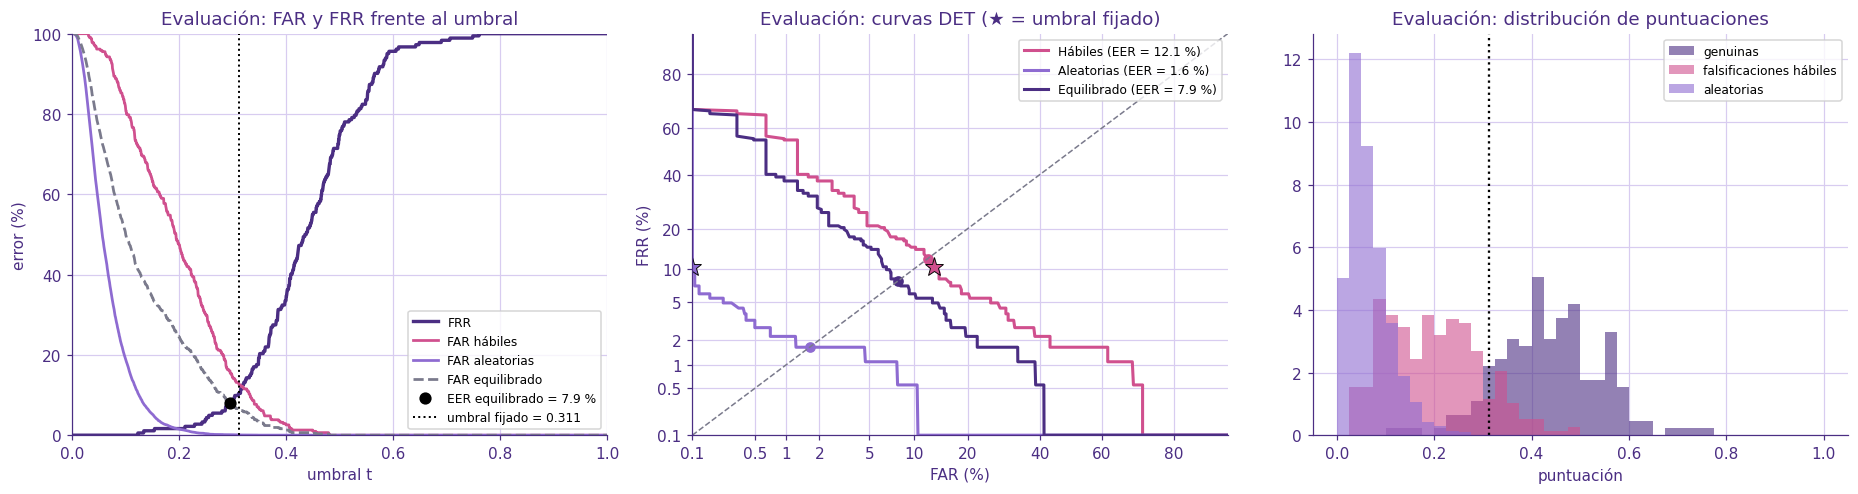

In [15]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.6))
grafica_far_frr(ejes[0], c_ev, 'Evaluación: FAR y FRR frente al umbral', UMBRAL)
grafica_det(ejes[1], c_ev, 'Evaluación: curvas DET (★ = umbral fijado)', UMBRAL, s_ev, tipo_ev)
for tipo_, color, nombre in (('genuina', LILA_OSCURO, 'genuinas'), ('hábil', ROSA, 'falsificaciones hábiles'), ('aleatoria', LILA, 'aleatorias')):
    ejes[2].hist(s_ev[tipo_ev == tipo_], bins=np.linspace(0, 1, 41), density=True, alpha=0.6, color=color, label=nombre)
ejes[2].axvline(UMBRAL, color='black', ls=':'); ejes[2].set_xlabel('puntuación'); ejes[2].set_title('Evaluación: distribución de puntuaciones')
ejes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Resultados por usuario
El umbral es global, así que no todos los usuarios quedan igual de bien: hay firmas muy estables y otras muy variables. Miramos los errores de cada usuario de evaluación con el umbral fijado.

,FRR (%),FAR hábiles (%),FAR aleatorias (%)
usuario,,,
31,0.0,4.2,0.0
32,0.0,0.0,0.0
33,0.0,4.2,0.0
34,7.1,66.7,0.0
35,28.6,12.5,0.9
36,21.4,4.2,0.0
37,0.0,70.8,0.2
38,0.0,0.0,0.0
39,7.1,0.0,0.0


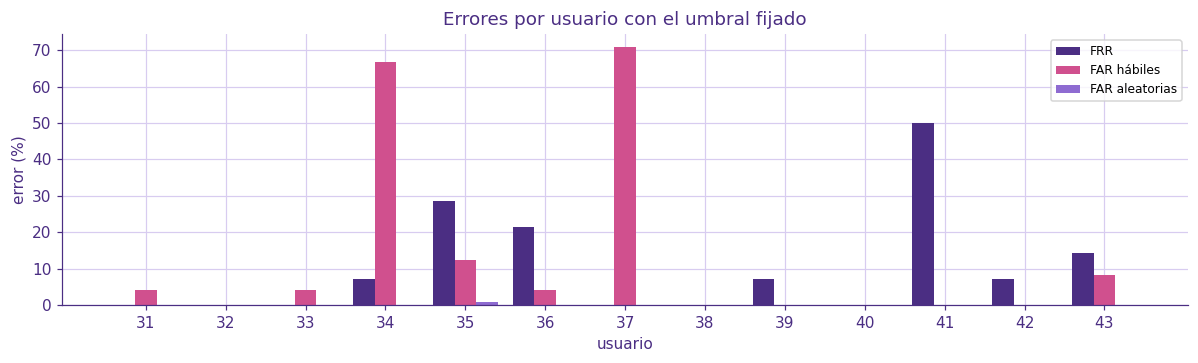

In [16]:
filas = []
for u in USUARIOS_EVALUACION:
    r = res_ev[res_ev.patron == u]
    filas.append({'usuario': u,
                  'FRR (%)': 100 * frr_en(r.puntuacion[r.tipo == 'genuina'].values, UMBRAL),
                  'FAR hábiles (%)': 100 * far_en(r.puntuacion[r.tipo == 'hábil'].values, UMBRAL),
                  'FAR aleatorias (%)': 100 * far_en(r.puntuacion[r.tipo == 'aleatoria'].values, UMBRAL)})
por_usuario = pd.DataFrame(filas).set_index('usuario')
display(por_usuario.round(1))

fig, ax = plt.subplots(figsize=(11, 3.4))
x = np.arange(len(por_usuario)); ancho = 0.27
ax.bar(x - ancho, por_usuario['FRR (%)'], ancho, color=LILA_OSCURO, label='FRR')
ax.bar(x, por_usuario['FAR hábiles (%)'], ancho, color=ROSA, label='FAR hábiles')
ax.bar(x + ancho, por_usuario['FAR aleatorias (%)'], ancho, color=LILA, label='FAR aleatorias')
ax.set_xticks(x); ax.set_xticklabels(por_usuario.index); ax.set_xlabel('usuario'); ax.set_ylabel('error (%)')
ax.set_title('Errores por usuario con el umbral fijado'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Discusión

**Resultados.** Con los 13 usuarios de evaluación y el umbral fijado en desarrollo (0.3115) obtenemos un EER de **12.1 %** frente a falsificaciones hábiles, **1.7 %** frente a impostores aleatorios y **7.9 %** en el escenario equilibrado. Con ese umbral, la FRR es del **10.4 %**, la FAR frente a falsificaciones hábiles del **13.1 %** y la FAR frente a aleatorias del **0.08 %**. En desarrollo los EER fueron 14.8 %, 2.3 % y 9.8 %. En la matriz de confusión esto se traduce en 19 genuinas rechazadas de 182 y 41 falsificaciones hábiles aceptadas de 312.

**Qué hemos visto**

- Las falsificaciones hábiles son mucho más difíciles que las aleatorias. Las firmas de otros usuarios se rechazan casi siempre, seguramente porque tienen otro tamaño, otra distribución de tinta y otro número de trazos, mientras que quien imita la firma consigue parecerse bastante en esas medidas globales. Como nuestras características miden la forma general y el reparto de la tinta, no el detalle del trazo, es normal que se les pase.
- Ponderar las características ayuda: en desarrollo el EER equilibrado baja de 12.4 % con pesos uniformes a 9.8 % con los de Fisher. Las que más pesan son el tamaño y la cantidad de tinta (`log_pixeles_tinta`, `log_alto`, `densidad_tinta`) y alguna orientación del trazo.
- La σ efectiva también influye: con α = 1 (solo la σ del usuario, que sale de solo 10 firmas) el error empeora, y los valores intermedios (0.25 a 0.75) van mejor. Al final nos quedamos con α = 0.25.
- Los resultados de evaluación salen algo mejores que los de desarrollo (7.9 % frente a 9.8 % de EER equilibrado). No le damos mucho importancia: con 13 usuarios y 182 genuinas de prueba cada firma mueve la FRR medio punto, y los usuarios varían mucho entre sí (tabla por usuario). Por ejemplo, los usuarios 34 y 37 aceptan muchas falsificaciones hábiles (FAR de 67 % y 71 %) y los usuarios 35 y 41 rechazan muchas de sus propias firmas (FRR de 29 % y 50 %).

**FAR o FRR: cuál importa más.** Depende de la aplicación. Si se usa para autorizar algo con consecuencias (un contrato, un pago, un documento legal), aceptar una falsificación es mucho peor que pedir al usuario que firme otra vez, así que interesa un umbral más alto con FAR baja aunque suba la FRR. Si es un uso de comodidad y bajo riesgo, un rechazo injusto molesta más que un fallo ocasional y se puede aceptar una FAR mayor con un umbral más bajo. En nuestro sistema, subir el umbral reduce la FAR frente a hábiles pero la FRR sube rápido (gráfica de FAR y FRR frente al umbral).

**Limitaciones**

- Usamos un único umbral global para todos los usuarios. Uno por usuario podría ayudar, pero con 10 referencias sería poco fiable.
- Solo tenemos 13 usuarios de evaluación, así que las cifras tienen bastante incertidumbre.
- El α y el umbral se eligieron con los mismos usuarios de desarrollo que se usan para mostrar su error, así que esos números de desarrollo son algo optimistas.


## 9. Guardar las puntuaciones y los parámetros

Guardamos las puntuaciones de evaluación de cada usuario con sus propias firmas (genuinas 11-24 y falsificaciones hábiles) en un CSV con usuario, firma, tipo y puntuación, para poder comparar más adelante con el otro sistema sobre exactamente las mismas firmas. También guardamos los parámetros fijados.

In [17]:
propias = res_ev[res_ev.tipo.isin(['genuina', 'hábil'])]
csv = pd.DataFrame({
    'usuario': propias.patron.values,
    'firma': [f"{'original' if c == 'g' else 'forgeries'}_{u}_{n}.png"
              for c, u, n in zip(propias.clase, propias.usuario, propias.n)],
    'tipo': np.where(propias.tipo == 'genuina', 'genuina', 'falsificación'),
    'puntuacion': propias.puntuacion.values.round(6),
})
csv.to_csv('puntuaciones_parametrico_evaluacion.csv', index=False, encoding='utf-8-sig')
np.savez('parametros_parametrico.npz', alfa=ALFA, umbral=UMBRAL, pesos=PESOS,
         sigma_global=SIGMA_GLOBAL, nombres=np.array(NOMBRES))

print(f'CSV guardado: {len(csv)} filas ({(csv.tipo == "genuina").sum()} genuinas, {(csv.tipo == "falsificación").sum()} falsificaciones)')
print(f'Parámetros fijados -> α = {ALFA}, umbral = {UMBRAL:.4f}, {len(NOMBRES)} características')
csv.head()

CSV guardado: 494 filas (182 genuinas, 312 falsificaciones)
Parámetros fijados -> α = 0.25, umbral = 0.3115, 35 características


,usuario,firma,tipo,puntuacion
0,31,original_31_11.png,genuina,0.468727
1,31,original_31_12.png,genuina,0.554963
2,31,original_31_13.png,genuina,0.562429
3,31,original_31_14.png,genuina,0.428208
4,31,original_31_15.png,genuina,0.648365
